In [4]:
from google.colab import drive
drive.mount('/content/drive')

# EDIT THESE TWO PATHS to match where you uploaded the extracted did-mdn folder
from pathlib import Path
CLEAN_DIR = Path('/content/drive/MyDrive/did-mdn/gt')
RAIN_DIR = Path('/content/drive/MyDrive/did-mdn/rainy')

assert CLEAN_DIR.exists(), f'Clean folder not found: {CLEAN_DIR}'
assert RAIN_DIR.exists(), f'Rainy folder not found: {RAIN_DIR}'
print('Clean folder:', CLEAN_DIR)
print('Rainy folder:', RAIN_DIR)

OUTPUT_DIR = Path('/content/outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clean folder: /content/drive/MyDrive/did-mdn/gt
Rainy folder: /content/drive/MyDrive/did-mdn/rainy


In [5]:
import random
import shutil
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import torchvision.utils as vutils
from PIL import Image
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

Using device: cuda


In [7]:
SUPPORTED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}


def image_paths(root_folder):
    """Recursively return all supported image files under root_folder."""
    root_folder = Path(root_folder)
    return sorted(p for p in root_folder.rglob('*') if p.suffix.lower() in SUPPORTED_EXTS)


def build_pairs(clean_folder, rainy_folder):
    """Match clean and rainy images: first by relative path (extension stripped),
    then falls back to matching by filename stem alone for anything unmatched."""
    clean_folder = Path(clean_folder)
    rainy_folder = Path(rainy_folder)
    clean_files = image_paths(clean_folder)
    rainy_files = image_paths(rainy_folder)

    rainy_by_relpath = {p.relative_to(rainy_folder).with_suffix(''): p for p in rainy_files}
    pairs = []
    unmatched = []
    for c in clean_files:
        rel = c.relative_to(clean_folder).with_suffix('')
        if rel in rainy_by_relpath:
            pairs.append((c, rainy_by_relpath[rel]))
        else:
            unmatched.append(c)

    if unmatched:
        rainy_by_stem = {p.stem: p for p in rainy_files}
        for c in unmatched:
            if c.stem in rainy_by_stem:
                pairs.append((c, rainy_by_stem[c.stem]))

    return pairs

In [8]:
class PairedRainDataset(Dataset):
    """Stores matched (clean, rainy) path pairs and whether random augmentation
    (horizontal flip) is enabled, i.e. training mode."""

    IMG_SIZE = 256

    def __init__(self, pairs, train=True):
        self.pairs = pairs
        self.train = train

    def __len__(self):
        return len(self.pairs)

    def _transform_pair(self, clean_img, rainy_img):
        clean_img = clean_img.convert('RGB')
        rainy_img = rainy_img.convert('RGB')

        clean_img = TF.resize(clean_img, [self.IMG_SIZE, self.IMG_SIZE])
        rainy_img = TF.resize(rainy_img, [self.IMG_SIZE, self.IMG_SIZE])

        if self.train and random.random() < 0.5:
            clean_img = TF.hflip(clean_img)
            rainy_img = TF.hflip(rainy_img)

        clean_tensor = TF.to_tensor(clean_img)
        rainy_tensor = TF.to_tensor(rainy_img)
        clean_tensor = TF.normalize(clean_tensor, mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
        rainy_tensor = TF.normalize(rainy_tensor, mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
        return clean_tensor, rainy_tensor

    def __getitem__(self, idx):
        clean_path, rainy_path = self.pairs[idx]
        clean_img = Image.open(clean_path)
        rainy_img = Image.open(rainy_path)
        return self._transform_pair(clean_img, rainy_img)

In [10]:
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

pairs = build_pairs(CLEAN_DIR, RAIN_DIR)
print(f'Found {len(pairs)} matched clean/rainy pairs.')

random.Random(SEED).shuffle(pairs)
n_val = max(1, int(0.1 * len(pairs)))
val_pairs = pairs[:n_val]
train_pairs = pairs[n_val:]
print(f'Train pairs: {len(train_pairs)}  |  Val pairs: {len(val_pairs)}  (90/10 split, seed=42)')

BATCH_SIZE_TRAIN = 4
BATCH_SIZE_VAL = 1

train_dataset = PairedRainDataset(train_pairs, train=True)
val_dataset = PairedRainDataset(val_pairs, train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE_TRAIN, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE_VAL, shuffle=False, num_workers=0)

# Sanity check on shapes
sample_clean, sample_rainy = train_dataset[0]
print(f'\nSample clean tensor: {sample_clean.shape}, range [{sample_clean.min():.2f}, {sample_clean.max():.2f}]')
print(f'Sample rainy tensor: {sample_rainy.shape}, range [{sample_rainy.min():.2f}, {sample_rainy.max():.2f}]')

Found 1201 matched clean/rainy pairs.
Train pairs: 1081  |  Val pairs: 120  (90/10 split, seed=42)

Sample clean tensor: torch.Size([3, 256, 256]), range [-1.00, 0.98]
Sample rainy tensor: torch.Size([3, 256, 256]), range [-0.99, 0.97]


In [11]:
class Down(nn.Module):
    """One downsampling block: strided conv (+ optional BatchNorm) + LeakyReLU(0.2)."""

    def __init__(self, in_channels, out_channels, normalize=True):
        super().__init__()
        layers = [nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=not normalize)]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class Up(nn.Module):
    """One upsampling block: transposed conv + BatchNorm + ReLU (+ optional Dropout),
    then channel-wise concatenation with the corresponding encoder skip feature."""

    def __init__(self, in_channels, out_channels, dropout=False):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        ]
        if dropout:
            layers.append(nn.Dropout(0.5))
        self.block = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.block(x)
        return torch.cat([x, skip], dim=1)


class UNetGenerator(nn.Module):
    """Encoder-decoder generator with skip connections. Input: clean RGB image.
    Output: generated rainy RGB image, same resolution (256x256 -> 256x256)."""

    def __init__(self):
        super().__init__()
        self.down1 = Down(3, 64, normalize=False)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)
        self.down4 = Down(256, 512)
        self.down5 = Down(512, 512)
        self.down6 = Down(512, 512)
        self.down7 = Down(512, 512)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
        )

        self.up1 = Up(512, 512, dropout=True)
        self.up2 = Up(1024, 512, dropout=True)
        self.up3 = Up(1024, 512, dropout=True)
        self.up4 = Up(1024, 512)
        self.up5 = Up(1024, 256)
        self.up6 = Up(512, 128)
        self.up7 = Up(256, 64)

        self.output = nn.Sequential(
            nn.ConvTranspose2d(128, 3, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)

        b = self.bottleneck(d7)

        u1 = self.up1(b, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)

        return self.output(u7)

In [12]:
class PatchDiscriminator(nn.Module):
    """Conditional PatchGAN discriminator: judges clean+rainy pairs, 6-channel input,
    outputs a patch-wise real/fake authenticity map."""

    def __init__(self):
        super().__init__()

        def block(in_c, out_c, stride, normalize=True):
            layers = [nn.Conv2d(in_c, out_c, kernel_size=4, stride=stride, padding=1, bias=not normalize)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(6, 64, stride=2, normalize=False),
            *block(64, 128, stride=2),
            *block(128, 256, stride=2),
            *block(256, 512, stride=1),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1),
        )

    def forward(self, clean_img, target_img):
        x = torch.cat([clean_img, target_img], dim=1)  # 6-channel conditional input
        return self.model(x)


def weights_init(m):
    """Conv/ConvTranspose: Normal(0, 0.02), bias 0. BatchNorm: Normal(1, 0.02), bias 0."""
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)

In [13]:
# Shape sanity check before training
_gen_check = UNetGenerator()
_disc_check = PatchDiscriminator()
_dummy_clean = torch.randn(2, 3, 256, 256)
_dummy_rainy = torch.randn(2, 3, 256, 256)
_fake = _gen_check(_dummy_clean)
print('Generator output shape:', tuple(_fake.shape), '(should match input 2,3,256,256)')
print('Discriminator output shape:', tuple(_disc_check(_dummy_clean, _dummy_rainy).shape), '(patch map)')
del _gen_check, _disc_check, _dummy_clean, _dummy_rainy, _fake


Generator output shape: (2, 3, 256, 256) (should match input 2,3,256,256)
Discriminator output shape: (2, 1, 30, 30) (patch map)


In [14]:
generator = UNetGenerator().to(DEVICE)
discriminator = PatchDiscriminator().to(DEVICE)
generator.apply(weights_init)
discriminator.apply(weights_init)

criterion_gan = nn.BCEWithLogitsLoss()
criterion_l1 = nn.L1Loss()

LR = 0.0002
BETAS = (0.5, 0.999)
LAMBDA_L1 = 100
N_EPOCHS = 50  # recommended starting point; increase if validation previews are still improving

optimizer_g = torch.optim.Adam(generator.parameters(), lr=LR, betas=BETAS)
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=LR, betas=BETAS)


def denormalize(tensor):
    """[-1, 1] -> [0, 1], clamped."""
    return (tensor * 0.5 + 0.5).clamp(0, 1)


def save_validation_preview(epoch, clean, fake_rain, real_rain):
    """Save one 3-image row: clean input | generated rainy | real rainy target."""
    grid = torch.cat([denormalize(clean), denormalize(fake_rain), denormalize(real_rain)], dim=0)
    vutils.save_image(grid, OUTPUT_DIR / f'val_epoch_{epoch:03d}.png', nrow=3)

In [15]:
g_loss_history, d_loss_history = [], []

for epoch in range(1, N_EPOCHS + 1):
    generator.train()
    discriminator.train()
    epoch_g_loss, epoch_d_loss = 0.0, 0.0

    for clean, real_rain in train_loader:
        clean = clean.to(DEVICE)
        real_rain = real_rain.to(DEVICE)

        # Step 2: generate rain
        fake_rain = generator(clean)

        # Step 3: train discriminator
        optimizer_d.zero_grad()
        pred_real = discriminator(clean, real_rain)
        loss_d_real = criterion_gan(pred_real, torch.ones_like(pred_real))
        pred_fake = discriminator(clean, fake_rain.detach())  # detach: no grad into G here
        loss_d_fake = criterion_gan(pred_fake, torch.zeros_like(pred_fake))
        loss_d = 0.5 * (loss_d_real + loss_d_fake)
        loss_d.backward()
        optimizer_d.step()

        # Step 4: train generator
        optimizer_g.zero_grad()
        pred_fake_for_g = discriminator(clean, fake_rain)  # not detached
        loss_g_gan = criterion_gan(pred_fake_for_g, torch.ones_like(pred_fake_for_g))
        loss_g_l1 = criterion_l1(fake_rain, real_rain) * LAMBDA_L1
        loss_g = loss_g_gan + loss_g_l1
        loss_g.backward()
        optimizer_g.step()

        epoch_g_loss += loss_g.item()
        epoch_d_loss += loss_d.item()

    avg_g = epoch_g_loss / len(train_loader)
    avg_d = epoch_d_loss / len(train_loader)
    g_loss_history.append(avg_g)
    d_loss_history.append(avg_d)
    print(f'Epoch {epoch}/{N_EPOCHS}  G_loss={avg_g:.4f}  D_loss={avg_d:.4f}')

    # Step 5: end-of-epoch validation preview
    generator.eval()
    with torch.no_grad():
        val_clean, val_real_rain = next(iter(val_loader))
        val_clean = val_clean.to(DEVICE)
        val_real_rain = val_real_rain.to(DEVICE)
        val_fake_rain = generator(val_clean)
        save_validation_preview(epoch, val_clean, val_fake_rain, val_real_rain)

    # Step 6: save checkpoint
    torch.save({
        'epoch': epoch,
        'generator_state_dict': generator.state_dict(),
        'discriminator_state_dict': discriminator.state_dict(),
        'optimizer_g_state_dict': optimizer_g.state_dict(),
        'optimizer_d_state_dict': optimizer_d.state_dict(),
    }, OUTPUT_DIR / 'latest.pt')

print('\nTraining complete. Checkpoint saved to', OUTPUT_DIR / 'latest.pt')

Epoch 1/50  G_loss=14.8573  D_loss=0.6419
Epoch 2/50  G_loss=13.3783  D_loss=0.5429
Epoch 3/50  G_loss=13.2382  D_loss=0.5681
Epoch 4/50  G_loss=13.2172  D_loss=0.5733
Epoch 5/50  G_loss=13.2286  D_loss=0.5862
Epoch 6/50  G_loss=13.3157  D_loss=0.5425
Epoch 7/50  G_loss=13.3755  D_loss=0.5728
Epoch 8/50  G_loss=13.3071  D_loss=0.5790
Epoch 9/50  G_loss=13.3883  D_loss=0.5659
Epoch 10/50  G_loss=13.3288  D_loss=0.5769
Epoch 11/50  G_loss=13.3659  D_loss=0.5696
Epoch 12/50  G_loss=13.4061  D_loss=0.5739
Epoch 13/50  G_loss=13.1879  D_loss=0.5900
Epoch 14/50  G_loss=13.4568  D_loss=0.5623
Epoch 15/50  G_loss=13.6666  D_loss=0.5297
Epoch 16/50  G_loss=13.5934  D_loss=0.5390
Epoch 17/50  G_loss=13.5304  D_loss=0.5257
Epoch 18/50  G_loss=13.7978  D_loss=0.4845
Epoch 19/50  G_loss=13.7538  D_loss=0.4855
Epoch 20/50  G_loss=13.8686  D_loss=0.4716
Epoch 21/50  G_loss=13.9052  D_loss=0.4826
Epoch 22/50  G_loss=13.5707  D_loss=0.5190
Epoch 23/50  G_loss=13.9342  D_loss=0.4545
Epoch 24/50  G_loss=

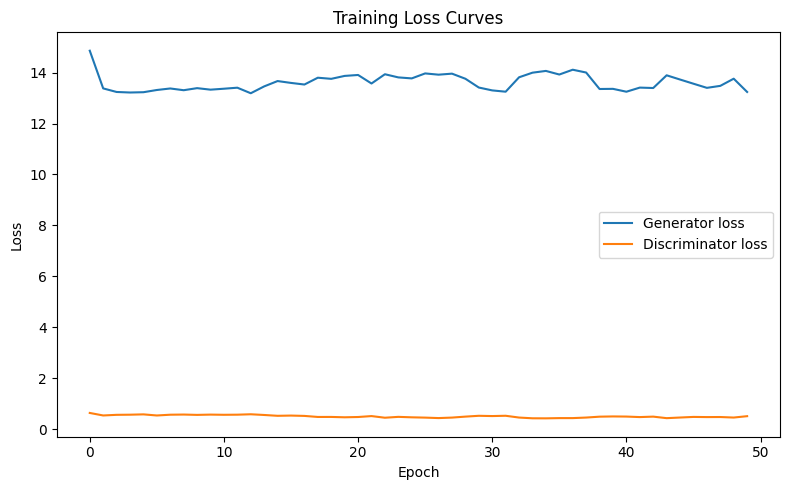

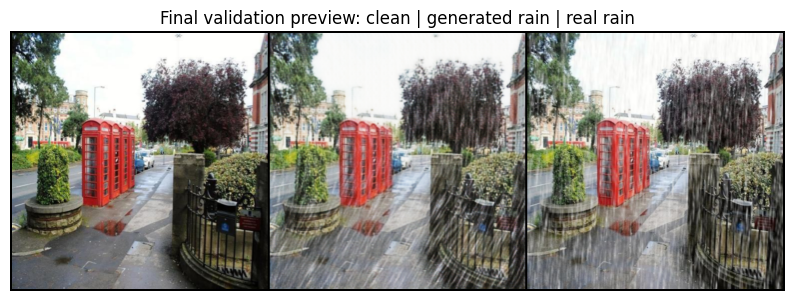

In [16]:
# Loss curves
plt.figure(figsize=(8, 5))
plt.plot(g_loss_history, label='Generator loss')
plt.plot(d_loss_history, label='Discriminator loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Curves')
plt.legend()
plt.tight_layout()
plt.show()

# Most recent validation preview
from PIL import Image as PILImage
preview = PILImage.open(OUTPUT_DIR / f'val_epoch_{N_EPOCHS:03d}.png')
plt.figure(figsize=(10, 4))
plt.imshow(preview)
plt.axis('off')
plt.title('Final validation preview: clean | generated rain | real rain')
plt.show()

In [17]:
def load_generator(checkpoint_path):
    gen = UNetGenerator().to(DEVICE)
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    gen.load_state_dict(checkpoint['generator_state_dict'])
    gen.eval()  # Step 1: eval mode; gradients disabled via torch.no_grad() below
    return gen


def preprocess_clean_image(image_path):
    """Same 256x256 resize + normalize transform used in training (no flip at inference)."""
    img = Image.open(image_path).convert('RGB')
    img = TF.resize(img, [256, 256])
    tensor = TF.to_tensor(img)
    tensor = TF.normalize(tensor, mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
    return tensor


def run_inference(clean_dir, output_dir, checkpoint_path):
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    gen = load_generator(checkpoint_path)

    clean_files = image_paths(clean_dir)
    print(f'Running inference on {len(clean_files)} clean images...')

    with torch.no_grad():  # Step 1 (cont.): disable gradients
        for path in clean_files:
            # Step 2: resize + normalize
            clean_tensor = preprocess_clean_image(path).unsqueeze(0).to(DEVICE)  # Step 3: add batch dim
            fake_rain = gen(clean_tensor)
            fake_rain = denormalize(fake_rain).squeeze(0).cpu()  # Step 4: [-1,1] -> [0,1], clamp

            out_name = f'{path.stem}_synthetic_rain{path.suffix}'
            TF.to_pil_image(fake_rain).save(output_dir / out_name)

    print(f'Saved {len(clean_files)} synthetic rain images to {output_dir}')

    # Step 5: zip and download
    zip_path = shutil.make_archive(str(output_dir), 'zip', root_dir=output_dir)
    print(f'Zipped results to {zip_path}')
    return zip_path


INFERENCE_OUTPUT_DIR = Path('/content/inference_outputs')
zip_path = run_inference(CLEAN_DIR, INFERENCE_OUTPUT_DIR, OUTPUT_DIR / 'latest.pt')

from google.colab import files
files.download(zip_path)

Running inference on 1203 clean images...
Saved 1203 synthetic rain images to /content/inference_outputs
Zipped results to /content/inference_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>